## First Assignment - The case of Boston

In [25]:
# ── imports ───────────────────────────────────────────────────────────────────
import json
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from ecomplexity import ecomplexity

# ── font sizes ────────────────────────────────────────────────────────────────
FS = 10
FS2 = FS - 2
FS4 = FS - 4

# ── paths ─────────────────────────────────────────────────────────────────────
RAW = "C:/Users/pc/Downloads/data/raw/"
PROCESSED = "C:/Users/pc/Downloads/data/processed/"
FOLDER = RAW + "POI_US_top50_metros/"

# ── choose a metro (file name without the .parquet ending) ────────────────────
METRO = "foursquare_14460_boston_places"

## 1. Clean the Foursquare categories

In [26]:
# ── clean categories ──────────────────────────────────────────────────────────
NOT_AMENITIES = [ # Pure geographic / natural features
    "Tree",
    "Lake",
    "River",
    "Forest",
    "Island",
    "Mountain",
    "Hill",
    "Bay",
    "Reservoir",
    "Canal",
    "Dam",
    "Well",
    "Cave",
    "Waterfall",

    # Infrastructure rather than an amenity
    "Road",
    "Bridge",
    "Tunnel",
    "Canal Lock",
    "Toll Booth",
    "Toll Plaza",
    "Border Crossing",

    # Administrative geography rather than a POI/service
    "States and Municipalities",

    # non-place
    "Moving Target",

    # Pure industrial/utility infrastructure
    "Power Plant",
    "Dump"]

In [27]:
def clean_categories(df):
    
    # 1. Drop POIs with no category
    before = len(df)
    df = df[df["fsq_category_labels"].notna()].copy()
    print(f"After removing missing categories: {len(df)} "
          f"(-{before - len(df)})")

    # 2. Drop closed POIs
    before = len(df)
    df = df[df["date_closed"].isna()].copy()
    print(f"After removing closed POIs: {len(df)} "
          f"(-{before - len(df)})")

    # 3. Create cleaned category
    df["categories"] = df["fsq_category_labels"].apply(
        lambda labels: labels[0].split(" > ")
    )

    df["top"] = df["categories"].apply(lambda x: x[0])

    df["category"] = df["categories"].apply(
        lambda x: x[1] if len(x) > 1 else x[0]
    )

    # 4. Drop non-amenities
    before = len(df)
    df = df[~df["category"].isin(NOT_AMENITIES)].copy()
    print(f"After removing non-amenities: {len(df)} "
          f"(-{before - len(df)})")

    # 5. Drop duplicate POIs
    before = len(df)
    df = df.drop_duplicates("fsq_place_id").copy()
    print(f"After removing duplicates: {len(df)} "
          f"(-{before - len(df)})")

    # 6. Make CBSA code a string
    df["cbsacode"] = df["cbsacode"].astype(str)

    return df
  

fs_df = pd.read_parquet(FOLDER + METRO + ".parquet")
print(f"All POIs: {len(fs_df)}")
fs_df = clean_categories(fs_df)
print(f"Clean POIs: {len(fs_df)}")
print(f"Unique categories: {fs_df['category'].nunique()}")

All POIs: 387309
After removing missing categories: 358176 (-29133)
After removing closed POIs: 330773 (-27403)
After removing non-amenities: 323723 (-7050)
After removing duplicates: 323723 (-0)
Clean POIs: 323723
Unique categories: 391


In [28]:
print(f"Unique top categories: {fs_df['top'].nunique()}")
print(f"Unique detailed categories: {fs_df['category'].nunique()}")
fs_df[["name", "fsq_category_labels", "top", "category"]].head(10)

Unique top categories: 10
Unique detailed categories: 391


,name,fsq_category_labels,top,category
0,Aidekman Performance Hanger,[Arts and Entertainment > Performing Arts Venue],Arts and Entertainment,Performing Arts Venue
1,Ua Flight 3413,[Travel and Transportation > Transport Hub > A...,Travel and Transportation,Transport Hub
2,James Harold Traynor CPA,[Business and Professional Services > Financia...,Business and Professional Services,Financial Service
3,Medway Garden Center,[Retail > Garden Center],Retail,Garden Center
4,Simon Willard Woods,[Landmarks and Outdoors > Hiking Trail],Landmarks and Outdoors,Hiking Trail
6,Team TUFGirl Athletics,[Sports and Recreation],Sports and Recreation,Sports and Recreation
7,NouveauDerm Medspa,[Health and Medicine > Physician > Dermatologist],Health and Medicine,Physician
9,Wedding Tresses Ma/Cape Cod Studio,[Business and Professional Services > Health a...,Business and Professional Services,Health and Beauty Service
10,Namaste Spice,[Dining and Drinking > Restaurant > Indian Res...,Dining and Drinking,Restaurant
12,Village Plaza,[Retail > Miscellaneous Store],Retail,Miscellaneous Store


In [29]:
# ── most frequent detailed categories ────────────────────────────────────────
fs_df["category"].value_counts().head(20)

category
Home Improvement Service              21109
Restaurant                            19949
Office                                16071
Financial Service                     14117
Education                             13846
Health and Beauty Service             12838
Physician                             10147
Automotive Service                     8195
Bar                                    7805
Real Estate Service                    6821
Fashion Retail                         6260
Structure                              5473
Gym and Studio                         5374
Transport Hub                          5326
Residential Building                   5195
Legal Service                          5008
Spiritual Center                       4615
Food and Beverage Retail               4494
Construction Supplies Store            4189
Business and Professional Services     4187
Name: count, dtype: int64

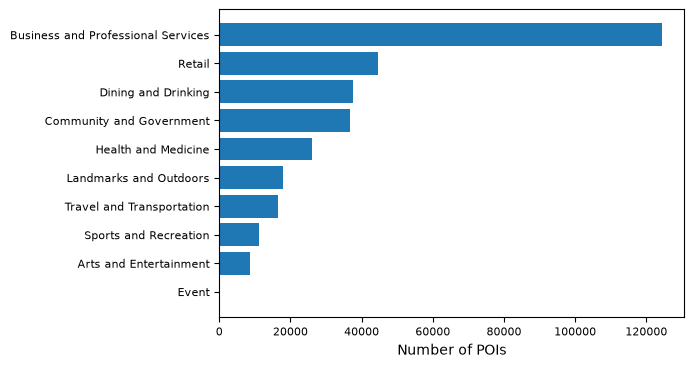

In [30]:
# ── bar chart: number of POIs by top category ────────────────────────────────
counts = fs_df["top"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(counts.index, counts.values, color="tab:blue")
ax.set_xlabel("Number of POIs", fontsize=FS)
ax.tick_params(labelsize=FS2)

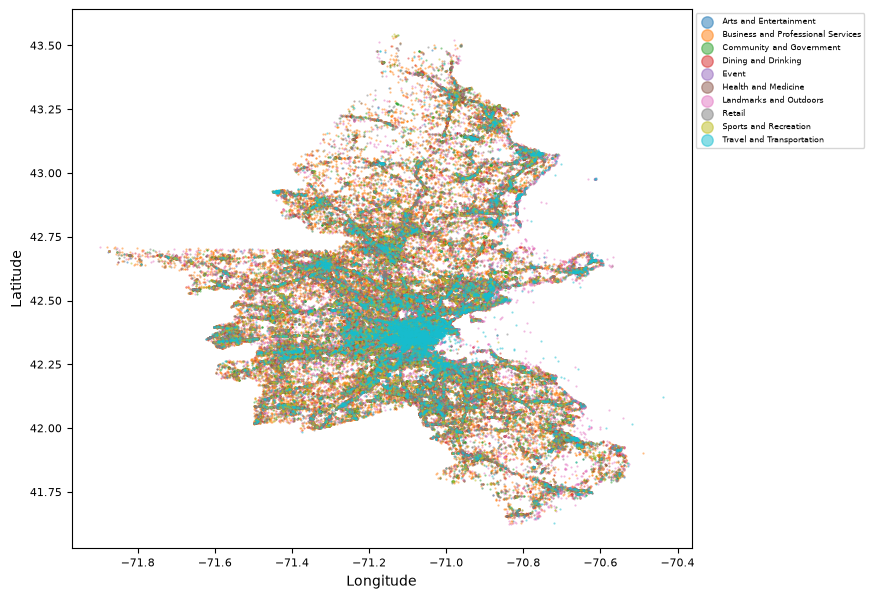

In [31]:
# ── map: POIs colored by top category ────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 7))
for top, group in fs_df.groupby("top"):
    ax.scatter(group["longitude"], group["latitude"], s=0.3, alpha=0.5, label=top)

ax.set_xlabel("Longitude", fontsize=FS)
ax.set_ylabel("Latitude", fontsize=FS)
ax.tick_params(labelsize=FS2)
ax.legend(fontsize=FS4, markerscale=15, loc="upper left", bbox_to_anchor=(1, 1))

In [32]:
# ── save cleaned POIs of this metro ───────────────────────────────────────────
cols = ["fsq_place_id", "name", "latitude", "longitude", "cbsacode", "top", "category"]
fs_df[cols].to_parquet(PROCESSED + METRO + "_clean.parquet", index=False)
print(f"Saved: data/processed/{METRO}_clean.parquet  ({len(fs_df)} rows)")

Saved: data/processed/foursquare_14460_boston_places_clean.parquet  (323723 rows)


## 2. Spatial join: POI → census tract

In [33]:
# ── load census tracts (one GeoJSON feature per line) ─────────────────────────
with open(RAW + "censustract_geoms_top50.geojson") as f:
    features = [json.loads(line) for line in f]
tracts = gpd.GeoDataFrame.from_features(features, crs="EPSG:4326")[["full_geoid", "geometry"]]

# ── assign every tract to a metro (tract centroid inside the metro polygon) ───
metros = gpd.read_file(RAW + "metro_areas/metro_areas.shp").to_crs("EPSG:4326")[["cbsacode", "geometry"]]
metros["cbsacode"] = metros["cbsacode"].astype(str)

centroids = tracts.copy()
centroids["geometry"] = tracts.to_crs("EPSG:5070").centroid.to_crs("EPSG:4326")
centroids = gpd.sjoin(centroids, metros, how="left", predicate="within")
tracts = tracts.merge(centroids[["full_geoid", "cbsacode"]].drop_duplicates("full_geoid"), on="full_geoid")

print(f"Tracts: {len(tracts)}  (without metro: {tracts['cbsacode'].isna().sum()})")

Tracts: 38788  (without metro: 219)


In [34]:
# ── spatial join: which tract is each POI in? ────────────────────────────────
def poi_to_tract(pois, tracts):
    points = gpd.GeoDataFrame(
        pois[["fsq_place_id", "category"]],
        geometry=gpd.points_from_xy(pois["longitude"], pois["latitude"]),
        crs="EPSG:4326",
    )
    joined = gpd.sjoin(points, tracts[["full_geoid", "geometry"]], how="inner", predicate="within")
    joined = joined.drop_duplicates("fsq_place_id")
    return joined[["fsq_place_id", "category", "full_geoid"]].rename(columns={
        "fsq_place_id": "POI_ID",
        "category": "POI_clean_category",
        "full_geoid": "census_tract_ID",
    })

cbsa = fs_df["cbsacode"].iloc[0]
poi_tract = poi_to_tract(fs_df, tracts[tracts["cbsacode"] == cbsa])

print(f"POIs matched to a tract: {len(poi_tract)} of {len(fs_df)}")
poi_tract.head()

POIs matched to a tract: 323673 of 323723


,POI_ID,POI_clean_category,census_tract_ID
0,4eaaed7d775bf08569c33ad9,Performing Arts Venue,14000US25017350600
1,5b099073b77c77002c55bbe1,Transport Hub,14000US25025981300
2,2a7e87816c514f056e438cc0,Financial Service,14000US33015051000
3,4ee3ab174690f8893fc67686,Garden Center,14000US25021408102
4,4d9b416803d8721ede85e324,Hiking Trail,14000US25017361100


## 3. Count POIs per tract and category

In [35]:
# ── groupby tract + category ─────────────────────────────────────────────────
counts = (poi_tract.groupby(["census_tract_ID", "POI_clean_category"])
          .size().rename("nr_amenities").reset_index())

print(f"Tracts: {counts['census_tract_ID'].nunique()}, categories: {counts['POI_clean_category'].nunique()}")
counts.head()

Tracts: 1006, categories: 391


,census_tract_ID,POI_clean_category,nr_amenities
0,14000US25009201100,Advertising Agency,1
1,14000US25009201100,Alternative Medicine Clinic,1
2,14000US25009201100,Arts and Entertainment,1
3,14000US25009201100,Assisted Living Service,1
4,14000US25009201100,Automotive Service,2


## 4. ECI for a single city

In [36]:
# Since the data represent one snapshot, a dummy time variable is used
counts["time"] = 0

# neighborhood = census tract
# amenity = cleaned Foursquare category
# value = number of POIs in that tract-category pair
cols_input = {
    "time": "time",
    "loc": "census_tract_ID",
    "prod": "POI_clean_category",
    "val": "nr_amenities"
}

# calculate complexity
result = ecomplexity(
    counts,
    cols_input,
    check_logsupermodularity=False,
    verbose=False
)

# ── amenity complexity of neighborhoods (ECI) ────────────────────────────────

eci_city = (
    result[
        ["census_tract_ID", "diversity", "eci"]
    ]
    .drop_duplicates()
    .sort_values("eci", ascending=False)
)

eci_city.head(10)

,census_tract_ID,diversity,eci
355419,14000US25025981300,34,7.946058
293641,14000US25025030300,115,6.035165
305762,14000US25025070101,104,5.864793
289731,14000US25025010702,79,4.733420
288949,14000US25025010600,88,4.415719
303416,14000US25025060600,99,4.372347
291686,14000US25025020301,48,4.020585
286603,14000US25025010300,37,3.973644
99314,14000US25017332400,92,3.719177
312800,14000US25025081001,40,3.611957


In [42]:
# ── complexity of amenities (PCI) ────────────────────────────────────────────

pci_amenities = (
    result[
        ["POI_clean_category", "ubiquity", "pci"]
    ]
    .drop_duplicates()
    .sort_values("pci", ascending=False)
)

pci_amenities.head(20)

,POI_clean_category,ubiquity,pci
155,Government Lobbyist,4,34.929589
326,Skydiving Center,2,26.432687
31,Ballroom,19,25.198418
333,Souvenir Store,12,25.071262
108,Duty-free Store,3,24.166299
237,Online Advertising Service,6,22.024520
87,Creperie,18,21.045804
191,Leather Goods Store,18,20.949447
312,Salsa Club,8,20.473627
314,Sauna,6,20.225676


In [43]:
# ── save single city ──────────────────────────────────────────────────────────
os.makedirs(PROCESSED, exist_ok=True)
counts.to_parquet(PROCESSED + METRO + "_tract_category_counts.parquet", index=False)
eci_city.to_parquet(PROCESSED + METRO + "_eci.parquet", index=False)

In [44]:
result[
    [
        "census_tract_ID",
        "POI_clean_category",
        "mcp",
        "diversity",
        "ubiquity",
        "eci",
        "pci"
    ]
].head(30)

,census_tract_ID,POI_clean_category,mcp,diversity,ubiquity,eci,pci
0,14000US25009201100,AIDS Resource,0,51,5,-0.331625,11.190128
1,14000US25009201100,Acupuncture Clinic,0,51,247,-0.331625,1.907523
2,14000US25009201100,Addiction Treatment Center,0,51,66,-0.331625,3.804469
3,14000US25009201100,Adult Store,0,51,24,-0.331625,7.501106
4,14000US25009201100,Advertising Agency,0,51,392,-0.331625,-0.260458
5,14000US25009201100,Agriculture and Forestry Service,0,51,155,-0.331625,-2.259641
6,14000US25009201100,Alternative Medicine Clinic,1,51,148,-0.331625,2.776147
7,14000US25009201100,Amusement Park,0,51,147,-0.331625,0.924708
8,14000US25009201100,Animal Shelter,0,51,142,-0.331625,-0.396702
9,14000US25009201100,Antique Store,0,51,274,-0.331625,-1.299705


## 5. ECI for all cities

ECI is calculated in two ways: separately within each metro, and on the pooled tract–amenity dataset across all 50 metros.

In [45]:
# ── clean + spatial join + count for ALL metros ──────────────────────────────
all_counts = []
for file in sorted(os.listdir(FOLDER)):
    if not file.endswith(".parquet"):
        continue
    df = clean_categories(pd.read_parquet(FOLDER + file))
    cbsa = df["cbsacode"].iloc[0]
    pt = poi_to_tract(df, tracts[tracts["cbsacode"] == cbsa])
    c = (pt.groupby(["census_tract_ID", "POI_clean_category"])
         .size().rename("nr_amenities").reset_index())
    c["cbsacode"] = cbsa
    all_counts.append(c)
    print(f"{file}: {len(pt)} POIs, {c['census_tract_ID'].nunique()} tracts")

all_counts = pd.concat(all_counts, ignore_index=True)
all_counts.to_parquet(PROCESSED + "tract_category_counts_top50.parquet", index=False)
print(f"Saved: {len(all_counts)} rows")

After removing missing categories: 444674 (-39527)
After removing closed POIs: 409720 (-34954)
After removing non-amenities: 398169 (-11551)
After removing duplicates: 398169 (-0)
foursquare_12060_atlanta_places.parquet: 398132 POIs, 951 tracts
After removing missing categories: 153992 (-14092)
After removing closed POIs: 135645 (-18347)
After removing non-amenities: 133235 (-2410)
After removing duplicates: 133235 (-0)
foursquare_12420_austin_places.parquet: 133230 POIs, 350 tracts
After removing missing categories: 177142 (-12705)
After removing closed POIs: 154363 (-22779)
After removing non-amenities: 149925 (-4438)
After removing duplicates: 149925 (-0)
foursquare_12580_baltimore_places.parquet: 149913 POIs, 682 tracts
After removing missing categories: 71661 (-6257)
After removing closed POIs: 66898 (-4763)
After removing non-amenities: 64390 (-2508)
After removing duplicates: 64390 (-0)
foursquare_13820_birmingham_places.parquet: 64387 POIs, 246 tracts
After removing missing cat

In [46]:
# ── ECI as a function (used for all cities) ──────────────────────────────────
def run_eci(counts):
    df = counts.copy()
    df["time"] = 0                         # one snapshot -> dummy time variable
    cols_input = {"time": "time", "loc": "census_tract_ID",
                  "prod": "POI_clean_category", "val": "nr_amenities"}
    result = ecomplexity(df, cols_input, check_logsupermodularity=False, verbose=False)
    return (result[["census_tract_ID", "diversity", "eci"]]
            .drop_duplicates()
            .sort_values("eci", ascending=False))

### 5.1 ECI calculated separately for each metro

In [ ]:
# (a) each city separately ─────────────────────────────
eci_per_city = []
for cbsa, group in all_counts.groupby("cbsacode"):
    e = run_eci(group.drop(columns="cbsacode"))
    e["cbsacode"] = cbsa
    eci_per_city.append(e)

eci_per_city = pd.concat(eci_per_city, ignore_index=True)
eci_per_city.to_parquet(PROCESSED + "eci_per_city_top50.parquet", index=False)
print(f"Tracts with ECI: {len(eci_per_city)}")

Tracts with ECI: 38556


### 5.2 ECI calculated on the pooled 50-metro dataset

In [ ]:
# (b) all tracts together (comparable across cities) ───
eci_all = run_eci(all_counts.drop(columns="cbsacode"))
eci_all.to_parquet(PROCESSED + "eci_pooled_top50.parquet", index=False)
print(f"Tracts with ECI: {len(eci_all)}")
eci_all["eci"].describe()

Tracts with ECI: 38556


count    3.855600e+04
mean    -9.435571e-17
std      1.000013e+00
min     -4.633949e+00
25%     -6.875361e-01
50%     -7.096261e-02
75%      6.199987e-01
max      6.287087e+00
Name: eci, dtype: float64